# Milestone 3 — Transfer Learning for Image Quality Assessment

## Overview

The objective of this milestone is to predict image quality using **Transfer Learning**.

Unlike our CNN baseline, which was trained from scratch, we use **ResNet-18**, a convolutional neural network pre-trained on ImageNet.

The idea is to reuse the visual features learned by ResNet-18 and adapt the model to predict the **Mean Opinion Score (MOS)** of images from the KonIQ-10k dataset.

We first use ResNet-18 as a **feature extractor**, then we will fine-tune part of the network to improve its performance.

Finally, we will compare the results with our previous CNN and RNN models.

## 1. Load Shared Data

We import the shared `TP2_Base.ipynb` notebook to reuse the dataset preparation and DataLoaders.

This ensures that the Transfer Learning model uses the same training, validation, and test images as our previous models, allowing a fair comparison.

We also import the PyTorch libraries and the pre-trained ResNet-18 model.

In [1]:
# Load shared data
%run ./TP2_Base.ipynb

import copy
from pathlib import Path

import torch.nn as nn
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import Subset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights

PyTorch: 2.13.0
Device: mps
Dataset size: 10073
Image shape: torch.Size([3, 128, 128])
MOS label: 3.83
Training samples: 8058
Validation samples: 1007
Test samples: 1008
Dimensions des images : torch.Size([32, 3, 128, 128])
Dimensions des labels : torch.Size([32])
Les 5 premiers MOS : tensor([3.6881, 3.6566, 3.0917, 3.5050, 2.2477])


## 2. Prepare Data for ResNet-18

ResNet-18 requires image preprocessing compatible with its pre-trained ImageNet weights.

We use the recommended transformations to resize, convert, and normalize the images.

We also keep the **same Train, Validation, and Test splits** as the CNN baseline.

Finally, we create new DataLoaders with a batch size of 32 to provide images to ResNet-18 during training and evaluation.

In [2]:

# Pre-trained weights and transformations
weights = ResNet18_Weights.DEFAULT
resnet_transform = weights.transforms()

# Create a dataset with the ResNet preprocessing
transfer_dataset = copy.copy(dataset)
transfer_dataset.transform = resnet_transform

# Reuse exactly the same splits
transfer_train = Subset(transfer_dataset, train_dataset.indices)
transfer_val = Subset(transfer_dataset, val_dataset.indices)
transfer_test = Subset(transfer_dataset, test_dataset.indices)

train_loader_tl = DataLoader(transfer_train, batch_size=32, shuffle=True)
val_loader_tl = DataLoader(transfer_val, batch_size=32, shuffle=False)
test_loader_tl = DataLoader(transfer_test, batch_size=32, shuffle=False)

print("Transfer Learning data ready!")

Transfer Learning data ready!


## 3. Load and Adapt ResNet-18

We load ResNet-18 with pre-trained ImageNet weights.

First, we **freeze the pre-trained layers** so their weights are not updated during training.

Then, we replace the original classification layer with a new fully connected layer:

`Linear(512, 1)`

This new layer produces a single value corresponding to the **predicted MOS**, instead of predicting one of the 1,000 ImageNet classes.

In this first experiment, only the new output layer will be trained.

In [3]:
# Load pre-trained ResNet18
model = resnet18(weights=weights)

# Freeze all pre-trained layers
for param in model.parameters():
    param.requires_grad = False

# Replace the classification layer
model.fc = nn.Linear(model.fc.in_features, 1)

# Send model to device
model = model.to(device)

print("ResNet18 model ready!")
print(model.fc)

ResNet18 model ready!
Linear(in_features=512, out_features=1, bias=True)


## 4. Loss Function and Optimizer

We use **Mean Squared Error (MSE)** as the loss function because image quality prediction is a regression task.

The **Adam optimizer** is used with a learning rate of 0.001.

Since the pre-trained ResNet-18 layers are frozen, the optimizer updates only the parameters of the new fully connected layer (`model.fc`).

The goal is to reduce the difference between the predicted MOS and the ground-truth MOS.

In [4]:
#loss function 
criterion = nn.MSELoss()

# Optimizer for the new regression layer (MOS prediction)
optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

## 5. Feature Extraction Training

In this step, we train only the new fully connected layer of ResNet-18 while keeping the pre-trained layers frozen.

The model predicts the MOS of each image, and the MSE loss measures the prediction error.

The Adam optimizer updates the new output layer to reduce this error. We also evaluate the model on the validation set after each epoch.

In [5]:

# Feature Extraction Training

num_epochs = 5
train_losses_fe = []
val_losses_fe = []

# Keep the best Feature Extraction model
best_val_fe = float("inf")
best_weights_fe = None

for epoch in range(num_epochs):

    # Keep frozen ResNet layers in evaluation mode
    model.eval()
    model.fc.train()

    train_loss = 0

    for images, mos in train_loader_tl:
        images = images.to(device)
        mos = mos.to(device).float().view(-1)

        optimizer.zero_grad()

        predictions = model(images).squeeze(1)
        loss = criterion(predictions, mos)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

    train_mse = train_loss / len(transfer_train)
    train_losses_fe.append(train_mse)

    # Validation
    model.eval()
    val_loss = 0

    with torch.no_grad():
        for images, mos in val_loader_tl:
            images = images.to(device)
            mos = mos.to(device).float().view(-1)

            predictions = model(images).squeeze(1)
            loss = criterion(predictions, mos)

            val_loss += loss.item() * images.size(0)

    val_mse = val_loss / len(transfer_val)
    val_losses_fe.append(val_mse)

    # Save weights when validation MSE improves
    if val_mse < best_val_fe:
        best_val_fe = val_mse
        best_weights_fe = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train MSE: {train_mse:.4f} | "
          f"Validation MSE: {val_mse:.4f}")

# Display the best result after training
print(f"\nBest Feature Extraction Validation MSE: {best_val_fe:.4f}")


Epoch 1/5 | Train MSE: 0.6430 | Validation MSE: 0.2988
Epoch 2/5 | Train MSE: 0.2576 | Validation MSE: 0.2444
Epoch 3/5 | Train MSE: 0.2136 | Validation MSE: 0.2317
Epoch 4/5 | Train MSE: 0.1982 | Validation MSE: 0.2003
Epoch 5/5 | Train MSE: 0.1926 | Validation MSE: 0.2008

Best Feature Extraction Validation MSE: 0.2003


## 6. Fine-Tuning ResNet-18

After training the output layer, we fine-tune the model by unfreezing the last ResNet block (`layer4`).

The earlier layers remain frozen, while `layer4` and the final regression layer can learn from the KonIQ-10k images.

We use a smaller learning rate to make gradual adjustments to the pre-trained weights.

In [6]:
# Start fine-tuning from the best Feature Extraction model
model.load_state_dict(best_weights_fe)

# Unfreeze the last ResNet block
for param in model.layer4.parameters():
    param.requires_grad = True

# Create a new optimizer
optimizer_ft = optim.Adam(
    [
        {"params": model.layer4.parameters(), "lr": 0.00001},
        {"params": model.fc.parameters(), "lr": 0.0001}
    ]
)

print("Fine-tuning ready!")


Fine-tuning ready!


In [7]:


# Fine-Tuning Training
num_epochs_ft = 5

train_losses_ft = []
val_losses_ft = []

# Save the best model
best_val_mse = float("inf")
best_epoch = 0
best_model_weights = None

for epoch in range(num_epochs_ft):

    # Training
    model.eval()
    model.layer4.train()
    model.fc.train()

    train_loss = 0

    for images, mos in train_loader_tl:
        images = images.to(device)
        mos = mos.to(device).float().view(-1)

        optimizer_ft.zero_grad()

        predictions = model(images).squeeze(1)
        loss = criterion(predictions, mos)

        loss.backward()
        optimizer_ft.step()

        train_loss += loss.item() * images.size(0)

    train_mse = train_loss / len(transfer_train)
    train_losses_ft.append(train_mse)

    # Validation
    model.eval()
    val_loss = 0

    with torch.no_grad():
        for images, mos in val_loader_tl:
            images = images.to(device)
            mos = mos.to(device).float().view(-1)

            predictions = model(images).squeeze(1)
            loss = criterion(predictions, mos)

            val_loss += loss.item() * images.size(0)

    val_mse = val_loss / len(transfer_val)
    val_losses_ft.append(val_mse)

    # Keep the best model
    if val_mse < best_val_mse:
        best_val_mse = val_mse
        best_epoch = epoch + 1
        best_model_weights = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch+1}/{num_epochs_ft} | "
          f"Train MSE: {train_mse:.4f} | "
          f"Validation MSE: {val_mse:.4f}")

print(f"\nBest epoch: {best_epoch}")
print(f"Best Validation MSE: {best_val_mse:.4f}")


Epoch 1/5 | Train MSE: 0.1583 | Validation MSE: 0.1522
Epoch 2/5 | Train MSE: 0.1104 | Validation MSE: 0.1410
Epoch 3/5 | Train MSE: 0.0826 | Validation MSE: 0.1261
Epoch 4/5 | Train MSE: 0.0669 | Validation MSE: 0.1208
Epoch 5/5 | Train MSE: 0.0550 | Validation MSE: 0.1232

Best epoch: 4
Best Validation MSE: 0.1208


## 7. Save the Best Fine-Tuned Model

We select the model with the lowest validation MSE during Fine-Tuning.

Instead of keeping the weights from the last epoch, we restore the weights from the best epoch and save them for future use.

In [8]:


# Restore the best model weights
model.load_state_dict(best_model_weights)
model.eval()

# Save the best model
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "resnet18_best.pth"

torch.save(model.state_dict(), model_path)

print(f"Model saved to: {model_path}")


Model saved to: ../models/resnet18_best.pth


## 8. Final Evaluation on the Test Set

We evaluate the best fine-tuned ResNet-18 model on the independent test set.

We calculate two metrics:

- **Test MSE:** the average squared error between predicted and actual MOS values.
- **Test RMSE:** the square root of MSE, which expresses prediction error in the MOS scale.

This evaluation measures the final model's performance on unseen images.

In [9]:

# Evaluate the best ResNet18 model on the test set

model.eval()
test_loss = 0

with torch.no_grad():
    for images, mos in test_loader_tl:
        images = images.to(device)
        mos = mos.to(device).float().view(-1)

        predictions = model(images).squeeze(1)

        loss = criterion(predictions, mos)
        test_loss += loss.item() * images.size(0)

# Calculate test metrics
test_mse = test_loss / len(transfer_test)
test_rmse = test_mse ** 0.5

print(f"Test MSE: {test_mse:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")


Test MSE: 0.1270
Test RMSE: 0.3564


## 9. Model Performance Comparison

We compare the performance of our CNN baseline, ResNet-18 Feature Extraction, and ResNet-18 Fine-Tuning.

The first chart compares the validation MSE of the three approaches. The second chart compares the test MSE of the CNN baseline and the fine-tuned ResNet-18 model.

A lower MSE indicates better MOS prediction accuracy. The tables and charts help visualize the improvements achieved through Transfer Learning.

,Model,Validation MSE,Test MSE
0,CNN Baseline,0.2372,0.2162
1,Feature Extraction,0.2003,NaN
2,Fine-Tuning,0.1208,0.1270


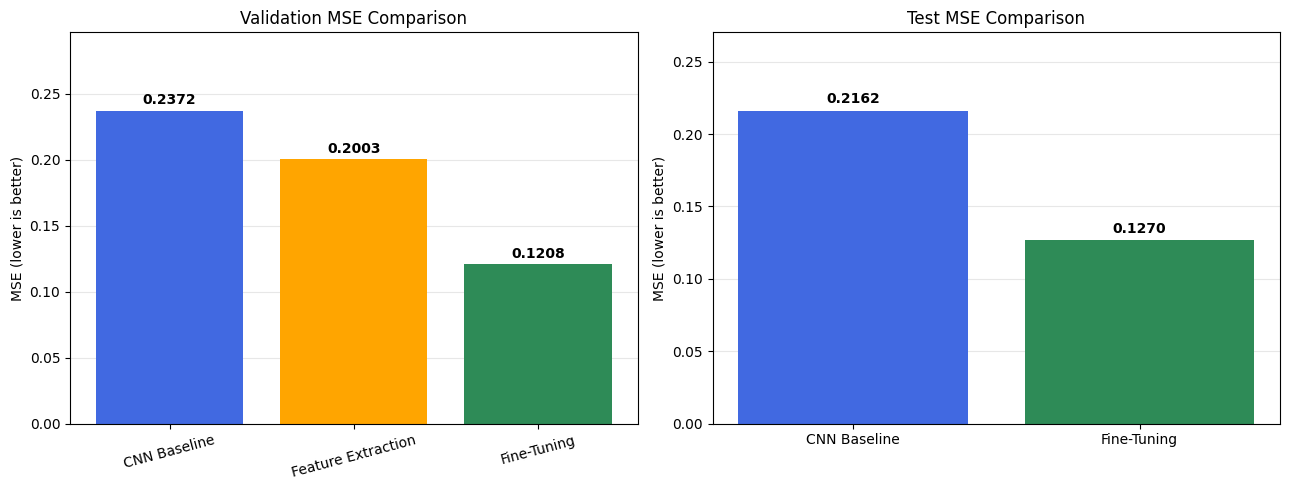

In [10]:

# Model Performance Comparison

# Validation results
cnn_val_mse = 0.2372
cnn_test_mse = 0.2162

feature_val_mse = min(val_losses_fe)
finetuning_val_mse = best_val_mse

# Comparison table
comparison = pd.DataFrame({
    "Model": [
        "CNN Baseline",
        "Feature Extraction",
        "Fine-Tuning"
    ],
    "Validation MSE": [
        cnn_val_mse,
        feature_val_mse,
        finetuning_val_mse
    ],
    "Test MSE": [
        cnn_test_mse,
        None,
        test_mse
    ]
})

display(comparison.round(4))

# Create two comparison charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Chart 1: Validation MSE
axes[0].bar(
    comparison["Model"],
    comparison["Validation MSE"],
    color=["royalblue", "orange", "seagreen"]
)

axes[0].set_title("Validation MSE Comparison")
axes[0].set_ylabel("MSE (lower is better)")
axes[0].tick_params(axis="x", rotation=15)

# Chart 2: Test MSE
test_models = ["CNN Baseline", "Fine-Tuning"]
test_values = [cnn_test_mse, test_mse]

axes[1].bar(
    test_models,
    test_values,
    color=["royalblue", "seagreen"]
)

axes[1].set_title("Test MSE Comparison")
axes[1].set_ylabel("MSE (lower is better)")

# Display values above bars
for ax in axes:
    for bar in ax.patches:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.005,
            f"{value:.4f}",
            ha="center",
            fontweight="bold"
        )

    ax.set_ylim(0, max(bar.get_height() for bar in ax.patches) * 1.25)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


## 10. Results Discussion and Conclusion

The results show that Transfer Learning improves image quality prediction compared to our CNN baseline.

ResNet-18 Feature Extraction achieved a validation MSE of **0.2003**, compared to **0.2372** for the CNN baseline.

After Fine-Tuning the last ResNet block, the validation MSE decreased further to **0.1208**, representing approximately a **49.1% reduction** compared to the CNN baseline.

The best Fine-Tuning result was obtained at **epoch 4**, and the corresponding model weights were selected for the final evaluation.

On the test set, the fine-tuned ResNet-18 achieved an MSE of **0.1270** and an RMSE of **0.3564**, compared to a test MSE of **0.2162** for the CNN baseline.

Overall, Fine-Tuning achieved the best performance among the evaluated models, showing the benefits of adapting pre-trained features to the Image Quality Assessment task.